In [1]:
import re
import pandas as pd

In [2]:
documents = {
    "Document 1": """
    Artificial Intelligence is a branch of computer science that focuses on
    creating machines capable of performing tasks that normally require human
    intelligence. These tasks include learning, reasoning, problem-solving,
    language understanding, and decision-making. Machine learning is a subset
    of artificial intelligence that enables computers to learn from data.
    Deep learning uses neural networks with multiple layers to learn complex
    patterns. AI is used in healthcare, education, finance, transportation,
    and many other industries.
    """,

    "Document 2": """
    Natural Language Processing is a field of artificial intelligence that
    enables computers to understand and process human language. NLP techniques
    include tokenization, stemming, lemmatization, sentiment analysis, and
    text classification. NLP applications include chatbots, machine
    translation, search engines, and virtual assistants. Modern NLP systems
    often use deep learning and transformer-based models to understand context.
    """
}

for title, text in documents.items():
    print(f"{title}:\n{text.strip()}\n")

Document 1:
Artificial Intelligence is a branch of computer science that focuses on
    creating machines capable of performing tasks that normally require human
    intelligence. These tasks include learning, reasoning, problem-solving,
    language understanding, and decision-making. Machine learning is a subset
    of artificial intelligence that enables computers to learn from data.
    Deep learning uses neural networks with multiple layers to learn complex
    patterns. AI is used in healthcare, education, finance, transportation,
    and many other industries.

Document 2:
Natural Language Processing is a field of artificial intelligence that
    enables computers to understand and process human language. NLP techniques
    include tokenization, stemming, lemmatization, sentiment analysis, and
    text classification. NLP applications include chatbots, machine
    translation, search engines, and virtual assistants. Modern NLP systems
    often use deep learning and transformer-

In [3]:
def clean_text(text):
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"[^\w\s.,!?'-]", "", text)
    return text.strip()

cleaned_documents = {
    title: clean_text(text)
    for title, text in documents.items()
}

for title, text in cleaned_documents.items():
    print(f"{title}: {text}\n")

Document 1: Artificial Intelligence is a branch of computer science that focuses on creating machines capable of performing tasks that normally require human intelligence. These tasks include learning, reasoning, problem-solving, language understanding, and decision-making. Machine learning is a subset of artificial intelligence that enables computers to learn from data. Deep learning uses neural networks with multiple layers to learn complex patterns. AI is used in healthcare, education, finance, transportation, and many other industries.

Document 2: Natural Language Processing is a field of artificial intelligence that enables computers to understand and process human language. NLP techniques include tokenization, stemming, lemmatization, sentiment analysis, and text classification. NLP applications include chatbots, machine translation, search engines, and virtual assistants. Modern NLP systems often use deep learning and transformer-based models to understand context.



In [4]:
def split_sentences(text):
    sentences = re.split(r"(?<=[.!?])\s+", text.strip())
    return [sentence.strip() for sentence in sentences if sentence.strip()]

for title, text in cleaned_documents.items():
    print(f"\n{title}")
    for i, sentence in enumerate(split_sentences(text), start=1):
        print(f"{i}. {sentence}")


Document 1
1. Artificial Intelligence is a branch of computer science that focuses on creating machines capable of performing tasks that normally require human intelligence.
2. These tasks include learning, reasoning, problem-solving, language understanding, and decision-making.
3. Machine learning is a subset of artificial intelligence that enables computers to learn from data.
4. Deep learning uses neural networks with multiple layers to learn complex patterns.
5. AI is used in healthcare, education, finance, transportation, and many other industries.

Document 2
1. Natural Language Processing is a field of artificial intelligence that enables computers to understand and process human language.
2. NLP techniques include tokenization, stemming, lemmatization, sentiment analysis, and text classification.
3. NLP applications include chatbots, machine translation, search engines, and virtual assistants.
4. Modern NLP systems often use deep learning and transformer-based models to unders

In [5]:
from collections import Counter

STOPWORDS = {
    "a", "an", "the", "is", "are", "was", "were", "be", "been",
    "to", "of", "and", "or", "in", "on", "for", "with", "that",
    "this", "it", "as", "by", "from", "at", "into", "their",
    "they", "these", "those", "can", "often", "many", "other"
}

def calculate_word_frequencies(text):
    words = re.findall(r"\b[a-zA-Z]+\b", text.lower())
    useful_words = [word for word in words if word not in STOPWORDS]
    return Counter(useful_words)

for title, text in cleaned_documents.items():
    frequencies = calculate_word_frequencies(text)
    print(f"\n{title} — Top words")
    print(frequencies.most_common(10))


Document 1 — Top words
[('intelligence', 3), ('learning', 3), ('artificial', 2), ('tasks', 2), ('learn', 2), ('branch', 1), ('computer', 1), ('science', 1), ('focuses', 1), ('creating', 1)]

Document 2 — Top words
[('nlp', 3), ('language', 2), ('understand', 2), ('include', 2), ('natural', 1), ('processing', 1), ('field', 1), ('artificial', 1), ('intelligence', 1), ('enables', 1)]


In [6]:
def score_sentences(text):
    sentences = split_sentences(text)
    word_frequencies = calculate_word_frequencies(text)

    if not word_frequencies:
        return []

    max_frequency = max(word_frequencies.values())

    normalized_frequencies = {
        word: frequency / max_frequency
        for word, frequency in word_frequencies.items()
    }

    scored_sentences = []

    for sentence in sentences:
        words = re.findall(r"\b[a-zA-Z]+\b", sentence.lower())
        score = sum(
            normalized_frequencies.get(word, 0)
            for word in words
            if word not in STOPWORDS
        )

        word_count = max(len(words), 1)
        normalized_score = score / word_count

        scored_sentences.append({
            "Sentence": sentence,
            "Score": normalized_score
        })

    return scored_sentences

for title, text in cleaned_documents.items():
    print(f"\n{title}")
    display(pd.DataFrame(score_sentences(text)))


Document 1


,Sentence,Score
0,Artificial Intelligence is a branch of compute...,0.318182
1,"These tasks include learning, reasoning, probl...",0.361111
2,Machine learning is a subset of artificial int...,0.333333
3,Deep learning uses neural networks with multip...,0.361111
4,"AI is used in healthcare, education, finance, ...",0.194444



Document 2


,Sentence,Score
0,Natural Language Processing is a field of arti...,0.277778
1,"NLP techniques include tokenization, stemming,...",0.393939
2,"NLP applications include chatbots, machine tra...",0.393939
3,Modern NLP systems often use deep learning and...,0.333333


In [7]:
def summarize_text(text, summary_sentences=3):
    sentences = split_sentences(text)

    if not sentences:
        return ""

    scored = score_sentences(text)

    ranked = sorted(
        enumerate(scored),
        key=lambda item: item[1]["Score"],
        reverse=True
    )

    selected_indices = sorted(
        index for index, _ in ranked[:min(summary_sentences, len(sentences))]
    )

    summary = " ".join(sentences[index] for index in selected_indices)
    return summary

for title, text in cleaned_documents.items():
    print(f"\n{title} — Summary")
    print(summarize_text(text, summary_sentences=3))


Document 1 — Summary
These tasks include learning, reasoning, problem-solving, language understanding, and decision-making. Machine learning is a subset of artificial intelligence that enables computers to learn from data. Deep learning uses neural networks with multiple layers to learn complex patterns.

Document 2 — Summary
NLP techniques include tokenization, stemming, lemmatization, sentiment analysis, and text classification. NLP applications include chatbots, machine translation, search engines, and virtual assistants. Modern NLP systems often use deep learning and transformer-based models to understand context.


In [8]:
comparison = []

for title, text in cleaned_documents.items():
    summary = summarize_text(text, summary_sentences=3)

    original_words = len(text.split())
    summary_words = len(summary.split())

    reduction = (
        (1 - summary_words / original_words) * 100
        if original_words else 0
    )

    comparison.append({
        "Document": title,
        "Original Words": original_words,
        "Summary Words": summary_words,
        "Reduction (%)": round(reduction, 2),
        "Summary": summary
    })

results_df = pd.DataFrame(comparison)
display(results_df)

,Document,Original Words,Summary Words,Reduction (%),Summary
0,Document 1,71,37,47.89,"These tasks include learning, reasoning, probl..."
1,Document 2,53,35,33.96,"NLP techniques include tokenization, stemming,..."


In [9]:
custom_text = input("Enter a paragraph to summarize:\n")

if custom_text.strip():
    sentence_count = len(split_sentences(custom_text))
    requested_sentences = int(
        input(f"Number of sentences in summary (1-{max(sentence_count, 1)}): ")
    )

    if sentence_count == 0:
        print("No valid sentences found.")
    else:
        requested_sentences = max(
            1, min(requested_sentences, sentence_count)
        )

        print("\nOriginal Text:\n", custom_text)
        print("\nGenerated Summary:\n",
              summarize_text(custom_text, requested_sentences))
else:
    print("Please enter some text.")

Enter a paragraph to summarize:
 The dodo was a very large, flightless bird that lived exclusively on the island of Mauritius.
Number of sentences in summary (1-1):  5



Original Text:
 The dodo was a very large, flightless bird that lived exclusively on the island of Mauritius.

Generated Summary:
 The dodo was a very large, flightless bird that lived exclusively on the island of Mauritius.


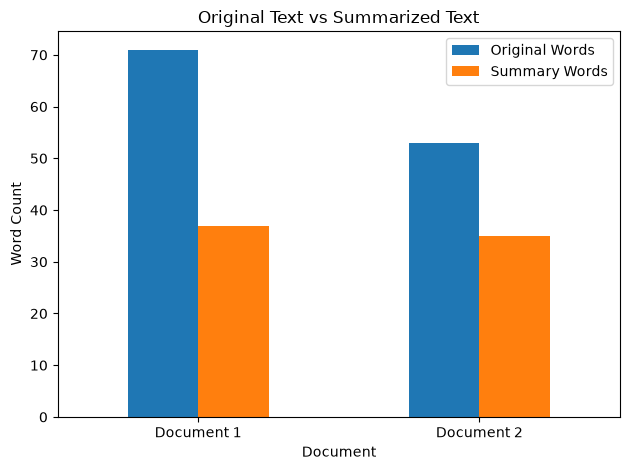

In [10]:
import matplotlib.pyplot as plt

plot_df = results_df.set_index("Document")[
    ["Original Words", "Summary Words"]
]

plot_df.plot(
    kind="bar",
    title="Original Text vs Summarized Text",
    xlabel="Document",
    ylabel="Word Count",
    rot=0
)

plt.tight_layout()
plt.show()